# Customer Churn Modeling ML Project

**📝 Problem Statement**

**Step 1: Import Libraries**

In [161]:
# data handling
import joblib
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# feature selection
from sklearn.feature_selection import VarianceThreshold

# classification models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

# metrics
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve



**Step 2: Load Dataset**

In [132]:
df = pd.read_csv("Churn_Modelling.csv")

**Step 3: Understand Your Data (EDA)**

In [103]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [104]:
df.sample(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
4590,4591,15680167,Thomson,635,France,Female,78,6,47536.40,1,1,1,119400.08,0
6950,6951,15667392,L?,652,Spain,Female,38,6,123081.84,2,1,1,188657.97,0
5813,5814,15763515,Shih,513,France,Male,30,5,0.00,2,1,0,162523.66,0
174,175,15625524,Rowe,512,France,Male,40,5,0.00,2,1,1,146457.83,0
7629,7630,15591107,Flemming,723,Germany,Female,68,3,110357.00,1,0,0,141977.54,1


In [105]:
df.shape

(10000, 14)

In [106]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

In [107]:
df.nunique()

RowNumber          10000
CustomerId         10000
Surname             2932
CreditScore          460
Geography              3
Gender                 2
Age                   70
Tenure                11
Balance             6382
NumOfProducts          4
HasCrCard              2
IsActiveMember         2
EstimatedSalary     9999
Exited                 2
dtype: int64

In [108]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [109]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


In [110]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

**Step 4: Data Cleaning**

In [111]:
# 1. check null values
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [133]:
# 2. remove duplicates
print("Duplicate values: ",df.duplicated().sum())
df = df.drop_duplicates()

Duplicate values:  0


In [137]:
# 3. remove unwanted cols
df.drop(columns=['RowNumber','CustomerId'], inplace=True)

In [139]:
# 4. fix col names
df = df.rename(columns={
    'Surname': 'surname', 
    'CreditScore': 'credit_score', 
    'Geography': 'geography', 
    'Gender': 'gender', 
    'Age': 'age', 
    'Tenure': 'tenure',
    'Balance': 'balance', 
    'NumOfProducts': 'num_of_products', 
    'HasCrCard': 'has_cr_card', 
    'IsActiveMember': 'is_active_member',
    'EstimatedSalary': 'estimated_salary', 
    'Exited': 'exited'
})


In [115]:
# 5. fix data types
# no need

<Axes: >

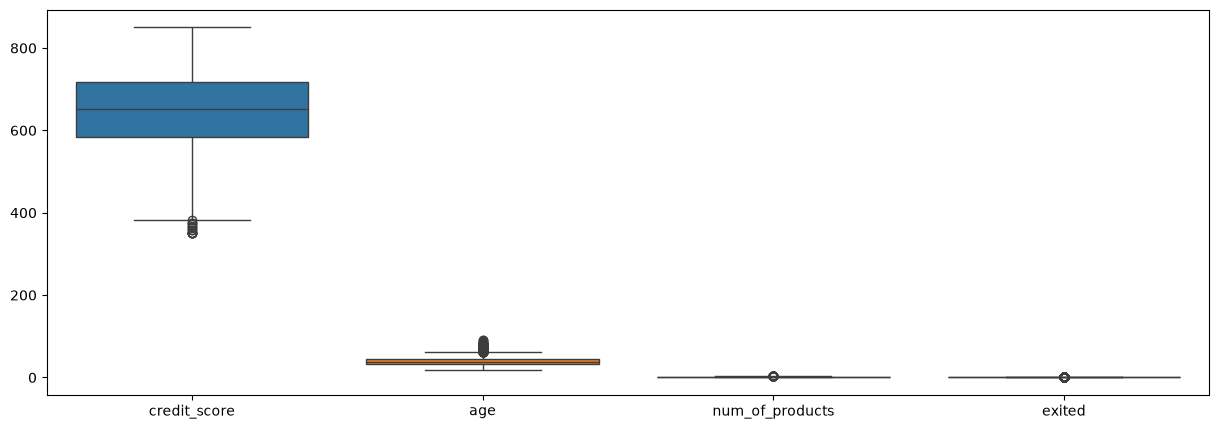

In [116]:
# 6. remove outliers
plt.figure(figsize=(15,5))
sns.boxplot(df[['credit_score', 'age', 'num_of_products','exited']])

In [141]:
cols = ['credit_score', 'age', 'num_of_products']
for i,col in enumerate(cols, start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower = q1 - (1.5 * iqr)
    upper = q3 + (1.5 * iqr)
    
    before_outliers = df[(df[col] < lower) | (df[col] > upper)]
    df[col] = df[col].clip(lower,upper)
    after_outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\n{i}. {col}")
    print(f"before outliers: {len(before_outliers)}")
    print(f"after outliers: {len(after_outliers)}")


1. credit_score
before outliers: 15
after outliers: 0

2. age
before outliers: 359
after outliers: 0

3. num_of_products
before outliers: 60
after outliers: 0


<Axes: >

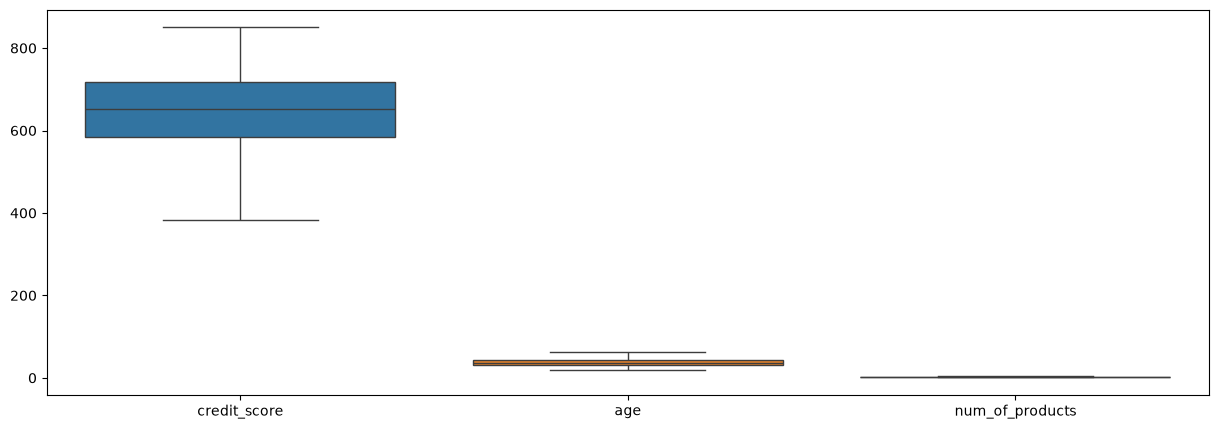

In [142]:
plt.figure(figsize=(15,5))
sns.boxplot(df[['credit_score', 'age', 'num_of_products']])

**Step 5: Feature Engineering**

In [143]:
df["balance_to_salary_ratio"] = df["balance"] / (df["estimated_salary"] + 1)
df["is_zero_balance"] = (df["balance"] == 0).astype(int)

df["products_per_year"] = df["num_of_products"] / (df["tenure"] + 1)
df["loyalty_score"] = df["tenure"] * df["is_active_member"]

df["credit_score_age_interaction"] = df["credit_score"] * df["age"]

df["age_group"] = pd.cut(df["age"],bins=[0, 30, 45, 60, np.inf],labels=["young", "middle_aged", "senior", "elderly"],)


**Step 6: Data Visualization**

Univariate:

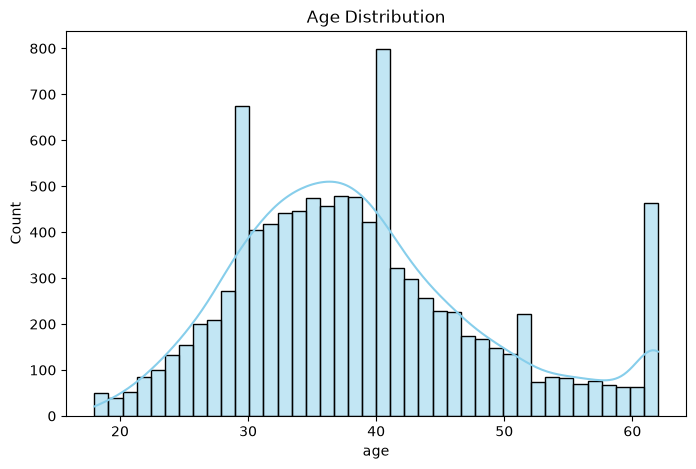

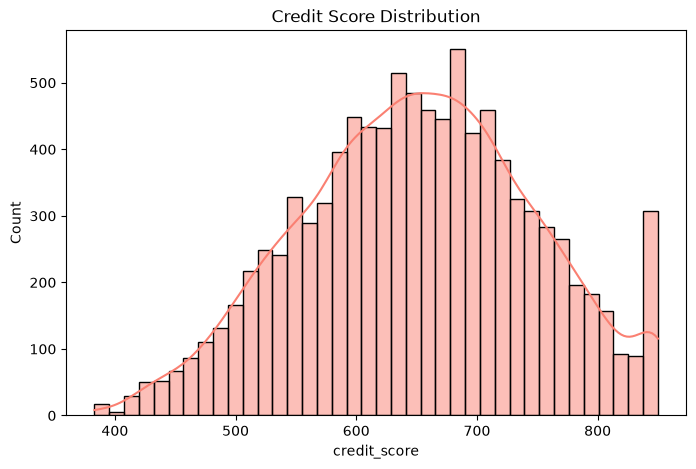

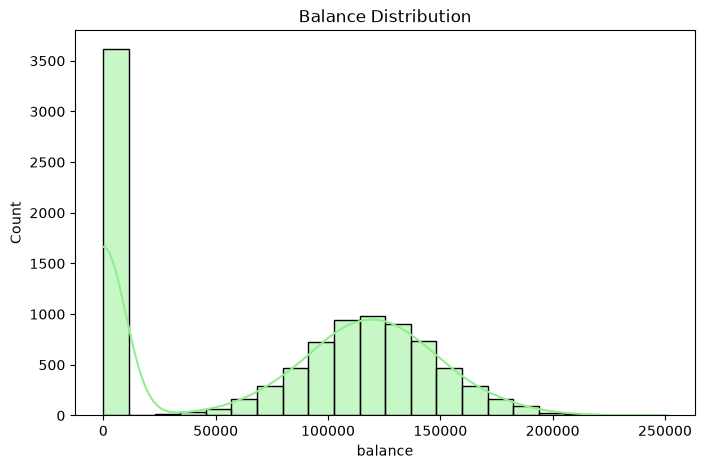

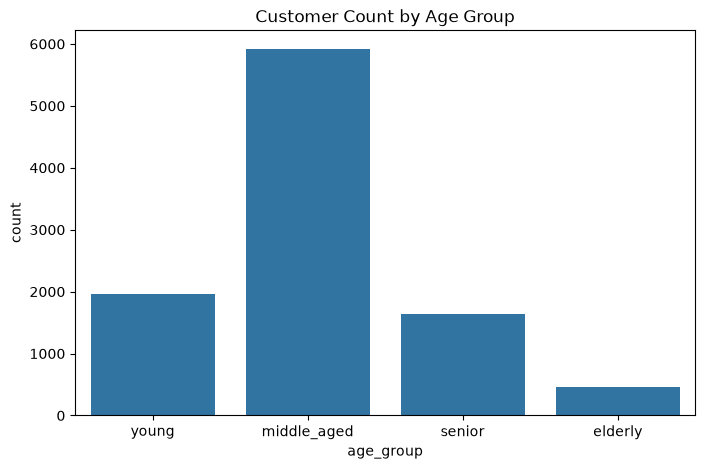

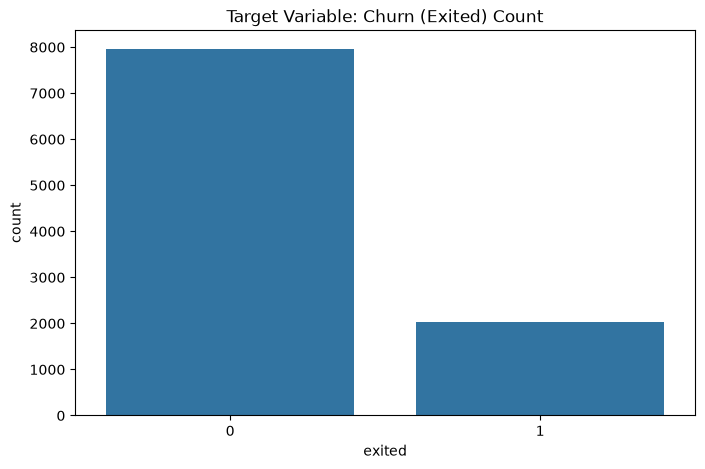

In [144]:
# --- CONTINUOUS VARIABLES ---

# Age Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["age"], kde=True, color="skyblue")
plt.title("Age Distribution")
plt.show()

# Credit Score Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["credit_score"], kde=True, color="salmon")
plt.title("Credit Score Distribution")
plt.show()

# Balance Distribution
plt.figure(figsize=(8, 5))
sns.histplot(df["balance"], kde=True, color="lightgreen")
plt.title("Balance Distribution")
plt.show()


# --- CATEGORICAL VARIABLES ---

# Age Group
plt.figure(figsize=(8, 5))
sns.countplot(x="age_group", data=df)
plt.title("Customer Count by Age Group")
plt.show()

# Target Variable (Exited)
plt.figure(figsize=(8, 5))
sns.countplot(x="exited", data=df)
plt.title("Target Variable: Churn (Exited) Count")
plt.show()

Bivariate & Multivariate:

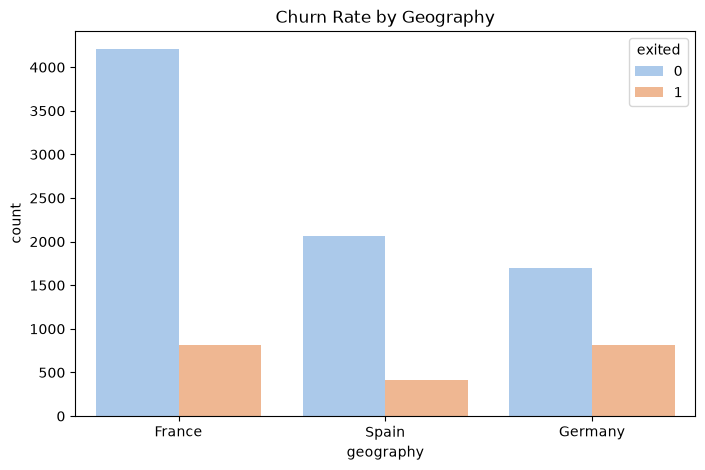

In [145]:
plt.figure(figsize=(8, 5))
sns.countplot(x="geography", hue="exited", data=df, palette="pastel")
plt.title("Churn Rate by Geography")
plt.show()


Correlation analysis:

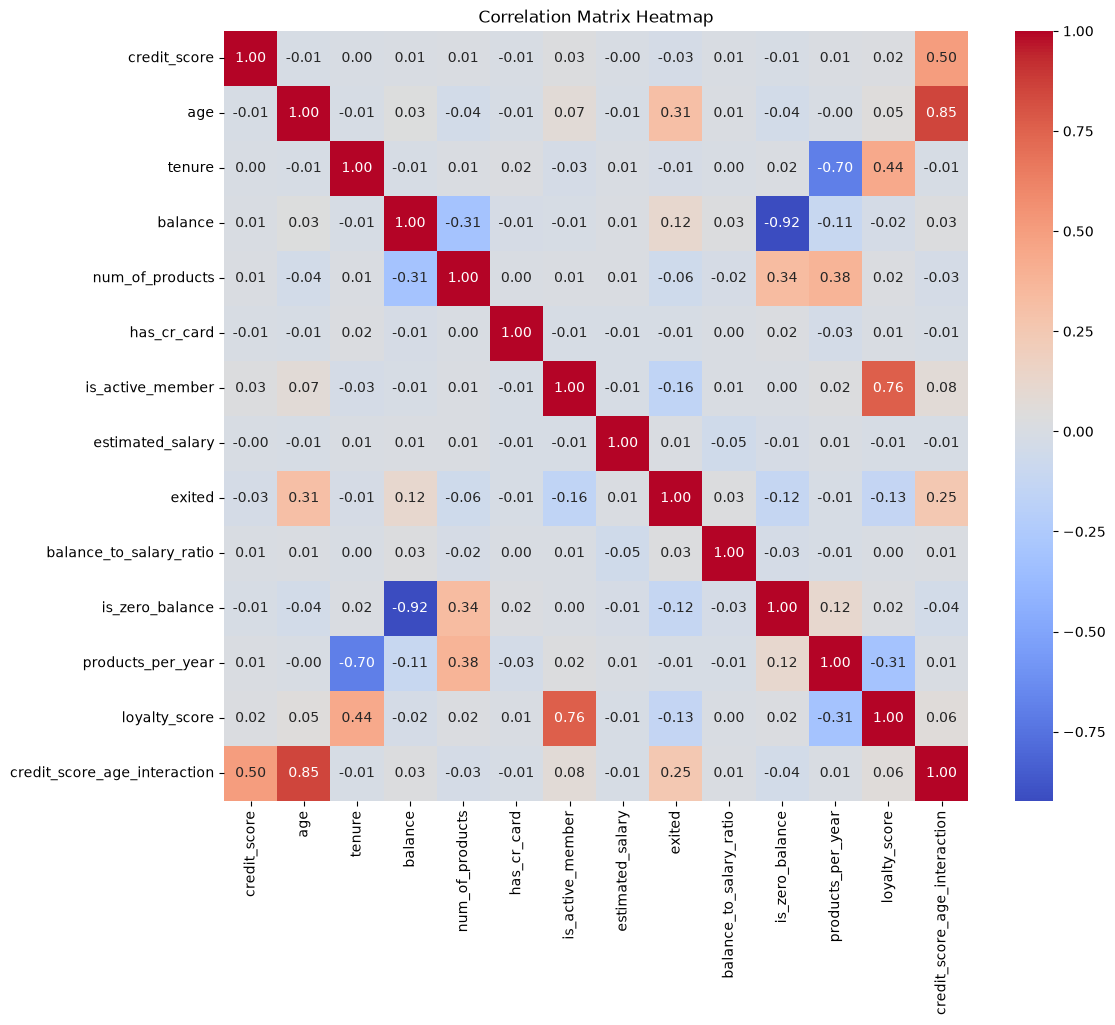

In [146]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

**Step 7: Define Features (X) and Target (y)**

In [147]:
X = df.drop(columns=['exited'])
y = df['exited']

num_cols = df.select_dtypes(include=[int,float]).drop(columns=['exited']).columns.to_list()
cat_cols = df.select_dtypes(include=['str','category']).columns.to_list()

**Step 8: Train-Test Split**

In [148]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (8000, 17) | X_test: (2000, 17)


**Step 9: Preprocessing Pipeline**

In [149]:
num_trans = Pipeline([
    ('imp',SimpleImputer(strategy='mean')),
    ('scr',StandardScaler())
])

cat_trans = Pipeline([
    ('imp',SimpleImputer(strategy='most_frequent')),
    ('ohe',OneHotEncoder(sparse_output=False, handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num_pre',num_trans,num_cols),
    ('cat_trans',cat_trans,cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [150]:
X_train_df = pd.DataFrame(X_train_processed, columns=preprocessor.get_feature_names_out())
X_test_df = pd.DataFrame(X_test_processed, columns=preprocessor.get_feature_names_out())

**Step 10: Feature Selection**

In [151]:
selector = VarianceThreshold(threshold=0.01)
X_train_sele = selector.fit_transform(X_train_df)
X_test_sele = selector.transform(X_test_df)
print("X_train shape before feature selection: ",X_train_df.shape)
print("X_train shape after feature selection: ",X_train_sele.shape)
print("\nX_test shape before feature selection: ",X_test_df.shape)
print("X_test shape after feature selection: ",X_test_sele.shape)

X_train shape before feature selection:  (8000, 2640)
X_train shape after feature selection:  (8000, 22)

X_test shape before feature selection:  (2000, 2640)
X_test shape after feature selection:  (2000, 22)


**Step 11 & 12: Train Models & Regression Metrics**

In [152]:
models = {
    "Logistic Regression":LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_split=5, min_samples_leaf=2,random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=200,max_depth=15, min_samples_split=2, min_samples_leaf=1, n_jobs=-1, random_state=42),
    "XgBoost":XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, random_state=42),
    "SVM": SVC(C=0.01, kernel='rbf', gamma='scale', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=8, n_jobs=-1),
    "Naive Bayes": GaussianNB()
}

for name, model in models.items():
    model.fit(X_train_sele, y_train)
    y_pred = model.predict(X_test_sele)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred,zero_division=0)
    pre = precision_score(y_test, y_pred,zero_division=0)
    re = recall_score(y_test, y_pred,zero_division=0)
    
    print(f"[{name}] -> Accuracy: {acc*100:.2f}%  -> F1: {f1*100:.4f} | Precision: {pre*100:.4f}  -> Recall: {re*100:.4f}")

[Logistic Regression] -> Accuracy: 83.60%  -> F1: 43.6426 | Precision: 67.1958  -> Recall: 32.3155
[Decision Tree] -> Accuracy: 85.05%  -> F1: 49.2360 | Precision: 73.9796  -> Recall: 36.8957
[Random Forest] -> Accuracy: 86.60%  -> F1: 58.1250 | Precision: 75.3036  -> Recall: 47.3282
[XgBoost] -> Accuracy: 86.10%  -> F1: 57.8788 | Precision: 71.5356  -> Recall: 48.6005
[SVM] -> Accuracy: 80.35%  -> F1: 0.0000 | Precision: 0.0000  -> Recall: 0.0000
[KNN] -> Accuracy: 84.05%  -> F1: 43.7390 | Precision: 71.2644  -> Recall: 31.5522
[Naive Bayes] -> Accuracy: 78.55%  -> F1: 48.3755 | Precision: 45.8904  -> Recall: 51.1450


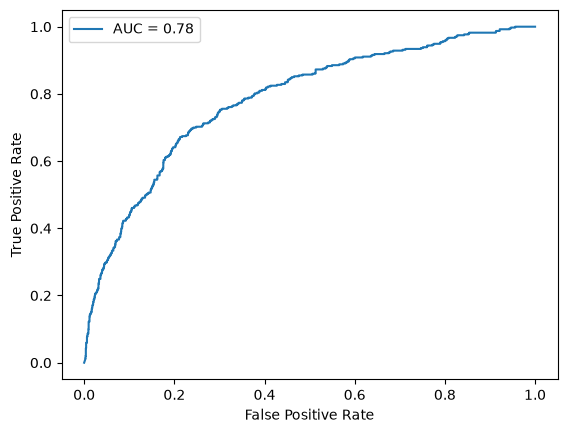

In [163]:
# Predicted probabilities
y_prob = model.predict_proba(X_test_sele)[:, 1]

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC
auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

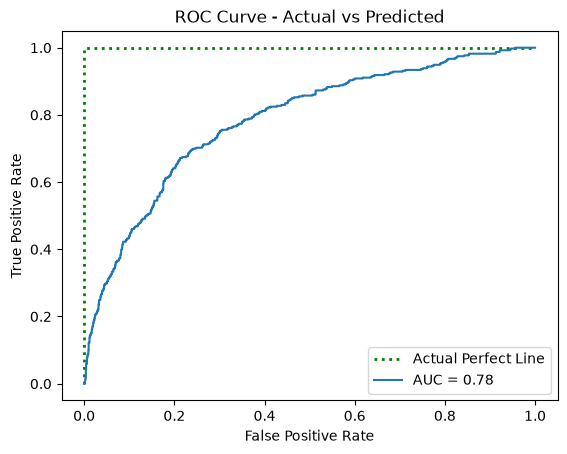

In [180]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

# 2. The perfect curve generated from your real test data (Actual)
fpr_actual, tpr_actual, _ = roc_curve(y_test, y_test)

plt.plot(fpr_actual,tpr_actual,label="Actual Perfect Line",color="green",linestyle=":",linewidth=2,)
plt.plot(fpr, tpr, label=f"AUC = {auc:.2f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Actual vs Predicted")
plt.legend()
plt.show()


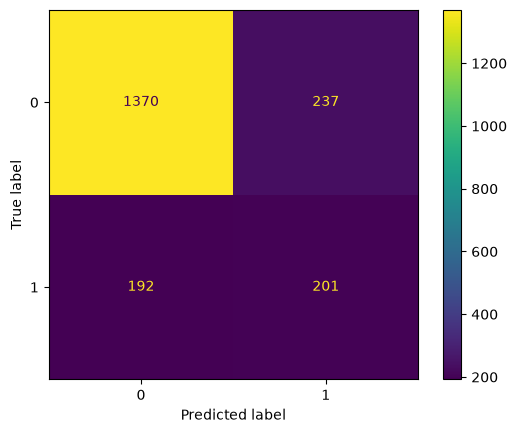

In [171]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

**Step 13: Cross Validation**

In [154]:
rf_validator = RandomForestClassifier(n_estimators=200,max_depth=15, min_samples_split=2, min_samples_leaf=1, n_jobs=-1, random_state=42)
cv_scores = cross_val_score(rf_validator, X_train_processed, y_train, cv=3, scoring='accuracy')

print(f"3-Fold Cross Validation Individual accuracy Matrix: {cv_scores}")
print(f"Mean Generalization R2 Accuracy: {cv_scores.mean()*100:.2f}%")


3-Fold Cross Validation Individual accuracy Matrix: [0.80689914 0.80427447 0.80495124]
Mean Generalization R2 Accuracy: 80.54%


**Step 14: Hyperparameter Tuning**

In [155]:
param_distributions = {
    'n_estimators': [100, 130, 150],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [5, 7, 4],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_validator,
    param_distributions=param_distributions,
    n_iter=5, 
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_processed, y_train)
best_tuned_rf = random_search.best_estimator_

print("Optimal Hyperparameter Configurations Found:", random_search.best_params_)


Optimal Hyperparameter Configurations Found: {'n_estimators': 150, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}


**Step 15: Feature Importance**

In [157]:
features = preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    'Feature': [name.split('__')[-1] for name in features], 
    'Importance': best_tuned_rf.feature_importances_                
}).sort_values(by='Importance', ascending=False)

print("\n--- TOP FEATURE IMPORTANCE SCORES ---")
print(importance.head(10))



--- TOP FEATURE IMPORTANCE SCORES ---
                           Feature  Importance
1                              age    0.084619
4                  num_of_products    0.078070
12    credit_score_age_interaction    0.066534
0                     credit_score    0.045329
2638              age_group_senior    0.043847
3                          balance    0.042012
7                 estimated_salary    0.041958
10               products_per_year    0.037561
8          balance_to_salary_ratio    0.035978
11                   loyalty_score    0.027296


**Step 16: Final Pipeline Production**

In [158]:
print("Unified Production Pipeline constructed successfully!")
production_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', best_tuned_rf)
])

production_pipeline.fit(X_train, y_train)

Unified Production Pipeline constructed successfully!


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['surname','credit_score','geography',...,'loyalty_score', 'credit_score_age_interaction','age_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pre', ...), ('cat_trans', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

**Step 17: Save Model & Load Model**

In [159]:
model_artifact = {
    "model_pipeline": production_pipeline,
    "feature_names": X.columns.tolist()
}

joblib.dump(model_artifact, "retail_rf_production.pkl")
print("Production artifact saved successfully as 'retail_rf_production.pkl'")

Production artifact saved successfully as 'retail_rf_production.pkl'


In [160]:
# --- Quick load verification test pass ---
loaded_bundle = joblib.load("retail_rf_production.pkl")
production_ready_rf_pipeline = loaded_bundle["model_pipeline"]
print("Model validation verified successfully! Ready for server deployment.")

Model validation verified successfully! Ready for server deployment.


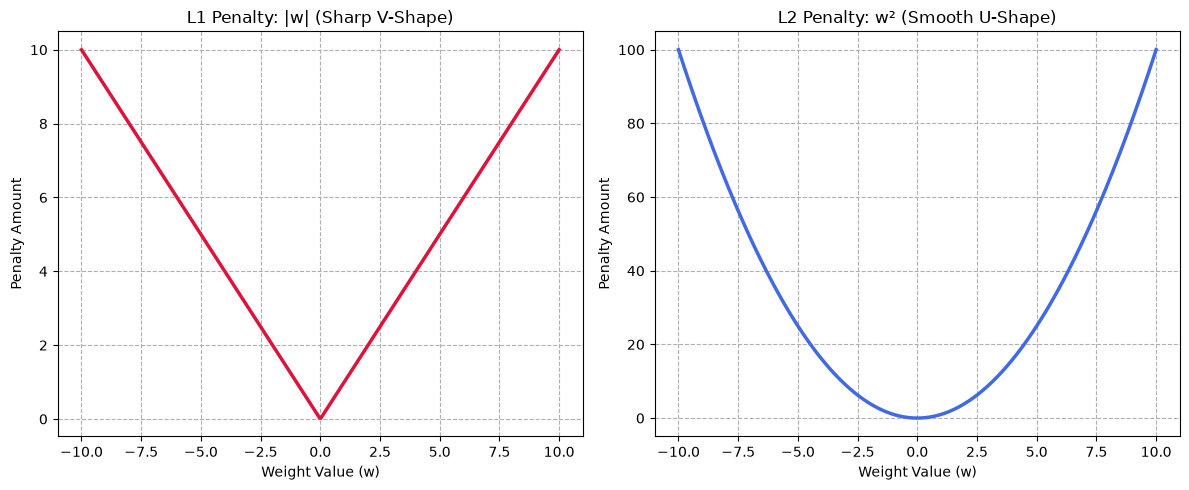

In [181]:
import matplotlib.pyplot as plt
import numpy as np

# Create a range of weight values from -10 to 10
w = np.linspace(-10, 10, 400)

# Calculate penalties
l1_penalty = np.abs(w)  # |w| creates the V-shape
l2_penalty = w**2  # w^2 creates the U-shape

# Plotting the shapes
plt.figure(figsize=(12, 5))

# 1. L1 Penalty (|w|) -> V-Shape
plt.subplot(1, 2, 1)
plt.plot(w, l1_penalty, color="crimson", linewidth=2.5)
plt.title("L1 Penalty: |w| (Sharp V-Shape)")
plt.xlabel("Weight Value (w)")
plt.ylabel("Penalty Amount")
plt.grid(True, linestyle="--")

# 2. L2 Penalty (w^2) -> U-Shape
plt.subplot(1, 2, 2)
plt.plot(w, l2_penalty, color="royalblue", linewidth=2.5)
plt.title("L2 Penalty: w² (Smooth U-Shape)")
plt.xlabel("Weight Value (w)")
plt.ylabel("Penalty Amount")
plt.grid(True, linestyle="--")

plt.tight_layout()
plt.show()
